# 3 · Choosing a graph builder

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vitormeriat/text4gcn/blob/main/docs/tutorials/03_choosing_a_graph_builder.ipynb)

The TextGCN graph of tutorial 2 connects two words whenever they co-occur
more often than chance. That gives **millions of edges**: most of the memory
and most of the build time.

The **Related Word Filter (RWF)** of Pereira & de Castro (DCAI 2022) asks a
simple question: *what if only related words were connected?* The semantic
variant trains Word2Vec on the corpus. It keeps a word–word edge only when the
two embeddings are very similar, and keeps the TF-IDF document–word edges
unchanged.

Here we build three graphs **on the same preprocessed corpus**, train the same
GCN on each and compare them.

> **Runtime:** about 6 min on a Colab T4 GPU and about 15 min on CPU.

| # | Tutorial | Question it answers |
|---|---|---|
| 1 | Text as a graph | What does the graph look like, and why does it help? |
| 2 | Your first classifier | How do I go from raw text to test accuracy? |
| 3 | **Choosing a graph builder** | How should words be connected? |
| 4 | Refining the graph | Can a smaller graph do as well? |
| 5 | Bring your own corpus | How do I use my own (non-English) data? |

In [ ]:
%pip install -q text4gcn
# Release candidate from TestPyPI (dependencies still come from PyPI):
# %pip install -q -i https://test.pypi.org/simple/ --extra-index-url https://pypi.org/simple/ "text4gcn==2.0.0rc2"

In [1]:
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from text4gcn import GNN, Builder, TextPipeline
from text4gcn.builder import Frequency, Semantic
from text4gcn.datasets import twenty_newsgroups

In [2]:
NAME = "20NG4"
DATA_DIR = Path("data")
LOG_DIR = Path("logs")
SEED = 1234
CATEGORIES = ["alt.atheism", "soc.religion.christian", "comp.graphics", "sci.med"]

Same data and preprocessing as tutorial 2: the graph is the only thing that changes.

In [3]:
shutil.rmtree(DATA_DIR, ignore_errors=True)   # TextPipeline never overwrites its outputs
twenty_newsgroups(DATA_DIR, name=NAME, categories=CATEGORIES)
TextPipeline(dataset_name=NAME, dataset_path=DATA_DIR, seed=SEED).execute(validation_ratio=0.10)

[2026/10/16 14:49:16] [INFO] ======================================== NLTK Configuration ========================================


[nltk_data] Downloading package stopwords to /home/vitor/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /home/vitor/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /home/vitor/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


[2026/10/16 14:49:17] [INFO] Random seed (shuffle) = <1234>
[2026/10/16 14:49:17] [INFO] Validation ratio = <0.1>
[2026/10/16 14:49:17] [INFO] 
[2026/10/16 14:49:17] [INFO] ============================= CLEANED DATA: Removed rare & stop-words. =============================
[2026/10/16 14:49:17] [INFO] Start process: 1792158557.1585748
[2026/10/16 14:49:18] [INFO] Rare-Count = <5>
[2026/10/16 14:49:18] [INFO] Elapsed time is 1.176782 seconds.
[2026/10/16 14:49:18] [INFO] 
[2026/10/16 14:49:18] [INFO] ============================ SHUFFLED DATA: Corpus documents shuffled. =============================
[2026/10/16 14:49:18] [INFO] Start process: 1792158558.3357751
[2026/10/16 14:49:18] [INFO] Elapsed time is 0.158468 seconds.
[2026/10/16 14:49:18] [INFO] 
[2026/10/16 14:49:18] [INFO] ======================= PREPARED WORDS: Vocabulary & word-vectors extracted. =======================
[2026/10/16 14:49:18] [INFO] Start process: 1792158558.4944112
[2026/10/16 14:49:23] [INFO] Elapsed time is 

/home/vitor/repos/Text4GNNs/text4gcn/text4gcn/modules/node_features.py:76: RuntimeWarning: invalid value encountered in divide
  mean_doc_vec = (doc_vec / len(words)).tolist()


[2026/10/16 14:49:25] [INFO] x.shape=(1973, 300), y.shape=(1973, 4)
[2026/10/16 14:49:25] [INFO] tx.shape=(1455, 300), ty.shape=(1455, 4)
[2026/10/16 14:49:25] [INFO] allx.shape=(13082, 300), ally.shape=(13082, 4)
[2026/10/16 14:49:25] [INFO] Elapsed time is 1.767713 seconds.
[2026/10/16 14:49:25] [INFO] 


## Three ways to connect words

| Graph | Word–word edges | `Builder` |
|---|---|---|
| **TF-IDF + PMI** (TextGCN) | positive PMI over a sliding window | `Builder.Tfidf` |
| **Word2Vec RWF** (DCAI 2022) | cosine similarity of corpus-trained Word2Vec embeddings > `threshold` | `Builder.Word2Vec` |
| **Cosine similarity** | cosine similarity of the TF-IDF word vectors saved by `TextPipeline` > `threshold` | `Builder.CosineSimilarity` |

All three keep the same TF-IDF document–word edges. Each builder writes its
own adjacency file, and `GNN(builder=...)` selects which one to train on.

In [4]:
graphs = {
    "TF-IDF + PMI": (Builder.Tfidf,
                     lambda: Frequency(dataset_name=NAME, dataset_path=DATA_DIR).tfidf(window_size=20)),
    "Word2Vec RWF": (Builder.Word2Vec,
                     lambda: Semantic(dataset_name=NAME, dataset_path=DATA_DIR).word2vec(
                         training_algorithm=1, embedding_dimension=300, num_epochs=20, threshold=0.95)),
    "Cosine similarity": (Builder.CosineSimilarity,
                          lambda: Semantic(dataset_name=NAME, dataset_path=DATA_DIR).cosine_similarity(
                              threshold=0.95)),
}

In [5]:
rows = []
for name, (builder, build) in graphs.items():
    start = time.perf_counter()
    stats = build()
    build_seconds = time.perf_counter() - start

    result = GNN(dataset_name=NAME, dataset_path=DATA_DIR, log_dir=LOG_DIR / builder.value,
                 builder=builder, seed=SEED).fit()
    rows.append({
        "graph": name,
        "edges": stats.n_edges,
        "file (MiB)": stats.file_bytes / 2**20,
        "build (s)": build_seconds,
        "test accuracy": result.test_accuracy,
        "epochs": result.epochs_trained,
    })

comparison = pd.DataFrame(rows).set_index("graph")
comparison.style.format({"edges": "{:,}", "file (MiB)": "{:.1f}", "build (s)": "{:.0f}",
                         "test accuracy": "{:.2%}"})

[2026/10/16 14:49:37] [INFO] =============== EXTRACTED ADJACENCY MATRIX: Heterogenous doc-word adjacency matrix. ================
[2026/10/16 14:49:37] [INFO] Start process: 1792158577.9978428
[2026/10/16 14:49:39] [INFO] Calculating PMI
[2026/10/16 14:53:27] [INFO] Calculating TF-IDF
[2026/10/16 14:53:29] [INFO] [INFO] (4534779, (4534779, 4534779)), shape=(14537, 14537)
[2026/10/16 14:53:31] [INFO] GraphBuildStats(frequency.tfidf: nodes=14537, edges(nnz)=4534779, density=2.145886e-02, file=51.95 MiB)
[2026/10/16 14:53:31] [INFO] Elapsed time is 233.523659 seconds.
[2026/10/16 14:53:31] [INFO] 
[2026/10/16 14:53:31] [WARN] Directory:'data/log' already exists, not overwritten.
Using device: cpu

============================== MODEL CONFIGURATION
Namespace(early_stopping=10, seed=1234, val_ratio=0.1, max_epoch=200, dataset='20NG4', dropout=0.5, log_dir=PosixPath('logs/frequency.tfidf'), layer=<Layer.GCN: 'GCN'>, nhid=200, lr=0.02, device=device(type='cpu'))


Show info about load data:



100%|██████████| 3647/3647 [00:11<00:00, 327.26it/s]


[INFO] Words without similarity: 477753
[INFO] Error in Compute Weights: 0
[2026/10/16 15:01:02] [INFO] (284545, (284545, 284545)), shape=(14537, 14537)
[2026/10/16 15:01:02] [INFO] GraphBuildStats(embedding.word2vec: nodes=14537, edges(nnz)=284545, density=1.346485e-03, file=3.31 MiB)
[2026/10/16 15:01:02] [WARN] Directory:'data/log' already exists, not overwritten.
Using device: cpu

============================== MODEL CONFIGURATION
Namespace(early_stopping=10, seed=1234, val_ratio=0.1, max_epoch=200, dataset='20NG4', dropout=0.5, log_dir=PosixPath('logs/embedding.word2vec'), layer=<Layer.GCN: 'GCN'>, nhid=200, lr=0.02, device=device(type='cpu'))


Show info about load data:

Data      Shape
--------  --------------
x         (1973, 300)
y         (1973, 4)
tx        (1455, 300)
ty        (1455, 4)
allx      (13082, 300)
ally      (13082, 4)
adj       (14537, 14537)
Features  (14537, 300)
Labels    (14537, 4)

Data statistics

  Edges    Classes    Train samples    Val samples    Te

100%|██████████| 11/11 [00:04<00:00,  2.54it/s]


[2026/10/16 15:07:40] [INFO] Calculating TF-IDF
[2026/10/16 15:07:42] [INFO] [INFO] (3221176, (3221176, 3221176)), shape=(14537, 14537)
[2026/10/16 15:07:43] [INFO] GraphBuildStats(cosine.similarity: nodes=14537, edges(nnz)=3221176, density=1.524280e-02, file=36.92 MiB)
[2026/10/16 15:07:43] [INFO] Elapsed time is 8.800624 seconds.
[2026/10/16 15:07:43] [INFO] 
Using device: cpu

============================== MODEL CONFIGURATION
Namespace(early_stopping=10, seed=1234, val_ratio=0.1, max_epoch=200, dataset='20NG4', dropout=0.5, log_dir=PosixPath('logs/cosine.similarity'), layer=<Layer.GCN: 'GCN'>, nhid=200, lr=0.02, device=device(type='cpu'))


Show info about load data:

Data      Shape
--------  --------------
x         (1973, 300)
y         (1973, 4)
tx        (1455, 300)
ty        (1455, 4)
allx      (13082, 300)
ally      (13082, 4)
adj       (14537, 14537)
Features  (14537, 300)
Labels    (14537, 4)

Data statistics

  Edges    Classes    Train samples    Val samples    Test samp

,edges,file (MiB),build (s),test accuracy,epochs
graph,,,,,
TF-IDF + PMI,"4,534,779",52.0,234,86.74%,52
Word2Vec RWF,"284,545",3.3,21,85.50%,50
Cosine similarity,"3,221,176",36.9,9,83.30%,46


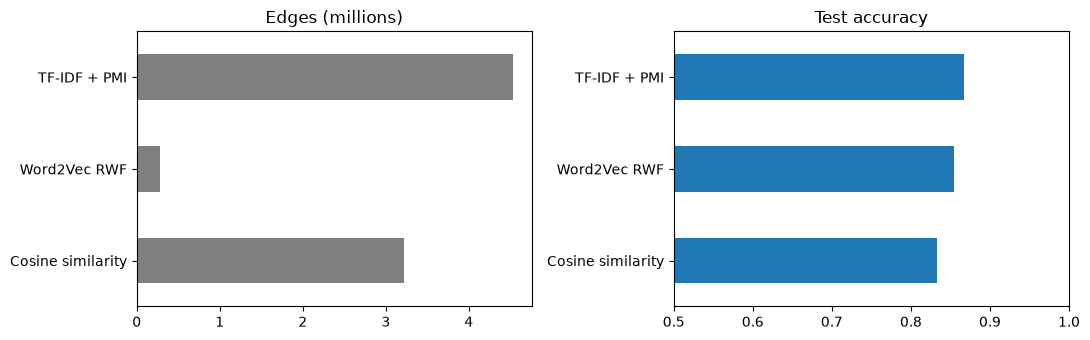

In [6]:
fig, (ax_edges, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.5))
(comparison["edges"] / 1e6).plot.barh(ax=ax_edges, color="tab:gray", title="Edges (millions)")
comparison["test accuracy"].plot.barh(ax=ax_acc, color="tab:blue", title="Test accuracy", xlim=(0.5, 1))
for ax in (ax_edges, ax_acc):
    ax.set_ylabel("")
    ax.invert_yaxis()
plt.tight_layout()

## Reading the results

On our CPU run (seed 1234), the **Word2Vec RWF graph had 16× fewer edges**
(0.28 M vs 4.5 M), a 3 MiB file instead of 52 MiB, and was built in about 10 s
instead of 90 s. Its accuracy stayed within about one point of the TextGCN
graph (85.5% vs 86.7%). This is the trade-off reported in the DCAI 2022 paper:
**much smaller graphs with comparable accuracy**. Exact numbers vary a little
with hardware.

The cosine-similarity graph kept 70% of the edges and lost about 3 points
(83.3%). Similar TF-IDF vectors only say that two words appear in the same
documents. Embeddings trained on the corpus capture relatedness better, so they
select better edges.

Which one to choose:

* **Start with TF-IDF + PMI.** It is the TextGCN baseline, and every paper compares against it.
* **Use Word2Vec RWF** when memory or build time matters, or with a larger corpus.
* **Tune `threshold`.** Lower values add edges, higher values prune more.
* The syntactic graphs (`Syntactic.dependency_parsing()`, `Syntactic.linguistic_inquiry()`)
  follow the same pattern but need Stanford CoreNLP or a LIWC dictionary. See the
  [builders guide](https://vitormeriat.github.io/text4gcn/guides/builders/).

**Next:** the builder decides which edges exist. [4 · Refining the graph](https://vitormeriat.github.io/text4gcn/tutorials/04_refining_the_graph/)
prunes an existing graph instead, without rebuilding it.